# Task 3 — HARD Scenario SHAP Analysis: Trajectory Background (100% Valid) vs. Synthetic Background

**Mục tiêu:**
- Trong bài báo (§2.3.4.2–2.3.4.3), độ nhạy SHAP theo background mới chỉ được báo cáo trên kịch bản **MEDIUM**, trong khi kiểm định hợp lệ vật lý cho thấy ở kịch bản **HARD**, **synthetic background chỉ đạt 84.5% hợp lệ** còn **trajectory background đạt 100% hợp lệ**.
- Notebook này chạy đối chiếu trực tiếp **SHAP ở kịch bản HARD** giữa `syn_random_100` (synthetic) và `traj_rollout_100` (trajectory rollout thật, 100% hợp lệ) cho cả **DQN** và **A2C_mod**, ở cả hai cấp độ:
  1. **Macro (3 đặc trưng, `KernelExplainer`)** — ~10 giây.
  2. **Micro (660 đặc trưng, `PartitionExplainer`)** — ~30–40 phút (có lưu `.npz` và tự động **resume** nếu bị ngắt).

**Đầu ra lưu tại:** `Feedback 23-11/task3/output/` (các file CSV, biểu đồ PNG, và `task3_summary.json`).


In [3]:
import os, sys, time, json, random, warnings, pathlib
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import shap
from scipy.stats import spearmanr

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Locate repository root automatically
REPO_ROOT = pathlib.Path.cwd()
for candidate in [
    REPO_ROOT,
    REPO_ROOT.parent,
    REPO_ROOT.parent.parent,
    pathlib.Path(r"C:\GitHub\Q-learning-for-Inventory-Management"),
]:
    if (candidate / "data" / "test.tfrecords").exists():
        REPO_ROOT = candidate
        break

DATA_DIR = REPO_ROOT / "data"
TASK3_DIR = REPO_ROOT / "Feedback 23-11" / "task3"
OUTPUT_DIR = TASK3_DIR / "output"
RAW_DIR = OUTPUT_DIR / "raw"
FIGS_DIR = OUTPUT_DIR / "figs"
for d in [OUTPUT_DIR, RAW_DIR, FIGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

A2C_CKPT_DIR = REPO_ROOT / "output Training" / "outputA2Cmod" / "checkpoints_a2cmod"
DQN_CKPT_DIR = REPO_ROOT / "output Training" / "checkpoints_dqn_comparison3primary"

# Experiment configuration
NUM_PRODUCTS = 220
NUM_FEATURES_PP = 3
NUM_FEATURES_660 = NUM_PRODUCTS * NUM_FEATURES_PP
NUM_ACTIONS = 14
BASE_WASTE_RATE = 0.025

# HARD scenario (consistent with task14-9 & task1)
HARD_SALES_SCALE = 1.5
HARD_WASTE_RATE = 0.05

N_TEST = 50
BG_SIZE = 100
TOP_K_LIST = [10, 20, 50]
FCS_THRESHOLD = 0.01

ACTION_LEVELS = np.array(
    [0.0, 0.005, 0.01, 0.0125, 0.015, 0.0175, 0.02, 0.03, 0.04, 0.08, 0.12, 0.2, 0.5, 1.0],
    dtype=np.float32,
)

print(f"TensorFlow: {tf.__version__} | SHAP: {shap.__version__}")
print(f"Repo root : {REPO_ROOT}")
print(f"Output dir: {OUTPUT_DIR}")
assert (DATA_DIR / "test.tfrecords").exists(), "Missing data/test.tfrecords!"
assert A2C_CKPT_DIR.exists(), f"Missing A2C checkpoint dir: {A2C_CKPT_DIR}"
assert DQN_CKPT_DIR.exists(), f"Missing DQN checkpoint dir: {DQN_CKPT_DIR}"
print("OK: All paths verified.")


TensorFlow: 2.20.0 | SHAP: 0.50.0
Repo root : c:\GitHub\Q-learning-for-Inventory-Management
Output dir: c:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\task3\output
OK: All paths verified.


## 1. Load Data & Real Trained Checkpoints (`DQN` và `A2C_mod`)

- Nạp đúng kiến trúc mạng thật: `Actor` (4 lớp, dropout=0 khi suy luận) và `MultiProductQNetwork` (3×128 + `GroupNormalization(groups=1)`, `training=False`).
- Xác nhận checkpoint nạp thành công (không fallback về trọng số ngẫu nhiên).


In [4]:
def sales_parser(serialized_example):
    return tf.io.parse_single_example(
        serialized_example, {"sales": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)}
    )

def capacity_parser(serialized_example):
    return tf.io.parse_single_example(
        serialized_example, {"capacity": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)}
    )

def stock_parser(serialized_example):
    return tf.io.parse_single_example(
        serialized_example, {"stock": tf.io.FixedLenFeature([NUM_PRODUCTS], tf.float32)}
    )

capacity = next(iter(tf.data.TFRecordDataset(str(DATA_DIR / "capacity.tfrecords")).map(capacity_parser)))["capacity"].numpy()
x_init = next(iter(tf.data.TFRecordDataset(str(DATA_DIR / "stock.tfrecords")).map(stock_parser)))["stock"].numpy()
all_sales_raw = np.array(
    [r["sales"].numpy() for r in tf.data.TFRecordDataset(str(DATA_DIR / "test.tfrecords")).map(sales_parser)],
    dtype=np.float32,
)
all_sales = all_sales_raw / capacity
print(f"Loaded test sales: {all_sales.shape}, x_init: {x_init.shape}, capacity: {capacity.shape}")

class Dense(tf.Module):
    def __init__(self, input_dim, output_size, activation=None, stddev=1.0):
        super().__init__()
        self.w = tf.Variable(tf.random.truncated_normal([input_dim, output_size], stddev=stddev), name="w")
        self.b = tf.Variable(tf.zeros([output_size]), name="b")
        self.activation = activation

    def __call__(self, x):
        y = tf.matmul(x, self.w) + self.b
        if self.activation:
            y = self.activation(y)
        return y

class Actor(tf.Module):
    def __init__(self, num_features=3, num_actions=14, hidden_size=32, activation=tf.nn.relu):
        super().__init__()
        self.layer1 = Dense(num_features, hidden_size)
        self.layer2 = Dense(hidden_size, hidden_size)
        self.layer3 = Dense(hidden_size, hidden_size)
        self.layer4 = Dense(hidden_size, num_actions)
        self.activation = activation

    def __call__(self, state):
        x = self.activation(self.layer1(state))
        x = self.activation(self.layer2(x))
        x = self.activation(self.layer3(x))
        return tf.nn.softmax(self.layer4(x), axis=-1)

class MultiProductQNetwork(tf.keras.Model):
    def __init__(self, num_features=660, num_products=220, num_actions=14, hidden_size=128, dropout_prob=0.1, use_group_norm=True):
        super().__init__()
        self.num_products = num_products
        self.num_actions = num_actions
        self.features_per_prod = num_features // num_products
        self.dense1 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.dense2 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.dense3 = tf.keras.layers.Dense(hidden_size, activation=None)
        self.out = tf.keras.layers.Dense(num_actions, activation=None)
        self._use_gn = use_group_norm
        if use_group_norm:
            self.gn1 = tf.keras.layers.GroupNormalization(groups=1)
            self.gn2 = tf.keras.layers.GroupNormalization(groups=1)
            self.gn3 = tf.keras.layers.GroupNormalization(groups=1)
        self.drop1 = tf.keras.layers.Dropout(dropout_prob)
        self.drop2 = tf.keras.layers.Dropout(dropout_prob)
        self.drop3 = tf.keras.layers.Dropout(dropout_prob)

    def call(self, state, training=False):
        B = tf.shape(state)[0]
        P, F = self.num_products, self.features_per_prod
        s3d = tf.transpose(tf.reshape(state, [B, F, P]), [0, 2, 1])
        x = tf.reshape(s3d, [B * P, F])
        x = self.dense1(x)
        if self._use_gn:
            x = self.gn1(x, training=training)
        x = tf.nn.relu(x)
        x = self.drop1(x, training=training)
        x = self.dense2(x)
        if self._use_gn:
            x = self.gn2(x, training=training)
        x = tf.nn.relu(x)
        x = self.drop2(x, training=training)
        x = self.dense3(x)
        if self._use_gn:
            x = self.gn3(x, training=training)
        x = tf.nn.relu(x)
        x = self.drop3(x, training=training)
        return tf.reshape(self.out(x), [B, P, self.num_actions])

# Restore A2C_mod
actor = Actor(num_features=3, num_actions=14, hidden_size=32)
_ = actor(tf.zeros([1, 3], dtype=tf.float32))
a2c_latest = tf.train.latest_checkpoint(str(A2C_CKPT_DIR))
assert a2c_latest is not None, f"No A2C checkpoint found in {A2C_CKPT_DIR}"
a2c_ckpt = tf.train.Checkpoint(actor=actor)
a2c_ckpt.restore(a2c_latest).expect_partial()
print(f"OK: A2C_mod restored: {a2c_latest} | layer1.w norm = {float(tf.norm(actor.layer1.w)):.4f}")

# Restore DQN (direct variable load via tf.train.load_variable — works identically on Keras 2 & Keras 3)
q_net = MultiProductQNetwork(num_features=660, num_products=220, num_actions=14, hidden_size=128)
_ = q_net(tf.zeros([1, 660], dtype=tf.float32), training=False)
dqn_latest = tf.train.latest_checkpoint(str(DQN_CKPT_DIR))
assert dqn_latest is not None, f"No DQN checkpoint found in {DQN_CKPT_DIR}"
w_before = float(tf.norm(q_net.dense1.kernel))

def _load_var(ckpt_path, key):
    return tf.train.load_variable(ckpt_path, f"{key}/.ATTRIBUTES/VARIABLE_VALUE")

dqn_layer_map = [
    (q_net.dense1.kernel, "q_network/dense1/kernel"),
    (q_net.dense1.bias,   "q_network/dense1/bias"),
    (q_net.dense2.kernel, "q_network/dense2/kernel"),
    (q_net.dense2.bias,   "q_network/dense2/bias"),
    (q_net.dense3.kernel, "q_network/dense3/kernel"),
    (q_net.dense3.bias,   "q_network/dense3/bias"),
    (q_net.gn1.gamma,     "q_network/gn1/gamma"),
    (q_net.gn1.beta,      "q_network/gn1/beta"),
    (q_net.gn2.gamma,     "q_network/gn2/gamma"),
    (q_net.gn2.beta,      "q_network/gn2/beta"),
    (q_net.gn3.gamma,     "q_network/gn3/gamma"),
    (q_net.gn3.beta,      "q_network/gn3/beta"),
    (q_net.out.kernel,    "q_network/out/kernel"),
    (q_net.out.bias,      "q_network/out/bias"),
]
for var, key in dqn_layer_map:
    arr = _load_var(dqn_latest, key)
    assert tuple(var.shape) == tuple(arr.shape), f"Shape mismatch for {key}: {var.shape} vs {arr.shape}"
    var.assign(arr)

w_after = float(tf.norm(q_net.dense1.kernel))
assert abs(w_after - w_before) > 1e-6, "DQN weights did not change after restore!"
print(f"OK: DQN restored    : {dqn_latest} | 14/14 tensors assigned | dense1.kernel norm = {w_after:.4f} (was {w_before:.4f})")

# Unified prediction wrappers (Common Quantity: portfolio-averaged softmax(Q) for DQN, policy pi for A2C_mod)
def a2c_predict_macro(X):
    X = np.asarray(X, dtype=np.float32)
    return actor(tf.constant(X, dtype=tf.float32)).numpy()

def dqn_predict_macro(X):
    X = np.asarray(X, dtype=np.float32)
    X660 = np.concatenate([
        np.repeat(X[:, 0:1], NUM_PRODUCTS, axis=1),
        np.repeat(X[:, 1:2], NUM_PRODUCTS, axis=1),
        np.repeat(X[:, 2:3], NUM_PRODUCTS, axis=1),
    ], axis=1).astype(np.float32)
    q = q_net(tf.constant(X660, dtype=tf.float32), training=False)
    return tf.nn.softmax(q[:, 0, :], axis=-1).numpy()

def a2c_predict_micro(X):
    X = np.asarray(X, dtype=np.float32)
    B = X.shape[0]
    s3d = tf.transpose(tf.reshape(tf.constant(X, dtype=tf.float32), [B, 3, NUM_PRODUCTS]), [0, 2, 1])
    probs = actor(tf.reshape(s3d, [B * NUM_PRODUCTS, 3]))
    probs_3d = tf.reshape(probs, [B, NUM_PRODUCTS, NUM_ACTIONS])
    return tf.reduce_mean(probs_3d, axis=1).numpy()

def dqn_predict_micro(X):
    X = np.asarray(X, dtype=np.float32)
    q = q_net(tf.constant(X, dtype=tf.float32), training=False)
    probs = tf.nn.softmax(q, axis=-1)
    return tf.reduce_mean(probs, axis=1).numpy()

# Quick sanity check
dummy3 = np.array([[0.5, 0.2, 0.025], [0.2, 0.8, 0.01]], dtype=np.float32)
dummy660 = np.random.uniform(0, 0.5, size=(2, 660)).astype(np.float32)
print("Sanity shapes:", a2c_predict_macro(dummy3).shape, dqn_predict_macro(dummy3).shape,
      a2c_predict_micro(dummy660).shape, dqn_predict_micro(dummy660).shape)


Loaded test sales: (504, 220), x_init: (220,), capacity: (220,)
OK: A2C_mod restored: c:\GitHub\Q-learning-for-Inventory-Management\output Training\outputA2Cmod\checkpoints_a2cmod\ckpt-64 | layer1.w norm = 9.1351
OK: DQN restored    : c:\GitHub\Q-learning-for-Inventory-Management\output Training\checkpoints_dqn_comparison3primary\ckpt-50 | 14/14 tensors assigned | dense1.kernel norm = 25.5367 (was 2.3858)
Sanity shapes: (2, 14) (2, 14) (2, 14) (2, 14)


## 2. Tạo tập Test HARD, Synthetic Background và Rollout Trajectory Background (100% hợp lệ)

- **Rollout thật ở kịch bản HARD** (`sales_scale = 1.5`, `waste_rate = 0.05`) trên 150 bước đầu tiên của `test.tfrecords`:
  - Bước `0..49` (`50` states): dùng làm tập **test states HARD** (không trùng với background).
  - Bước `50..149` (`100` states): dùng làm **Trajectory Background (`traj_rollout_100`)** — cả 3 biến *Inventory, Demand, Waste* đều biến thiên tự nhiên theo động lực học thật và đảm bảo **100% hợp lệ vật lý**.
- **Synthetic Background (`syn_random_100`)**: giữ nguyên đúng quy trình baseline của bài báo (`inv ~ U(0,1)`, `sales ~ U(0,1)`, `waste = clip(0.025*inv + N(0, 0.005), 0, 0.1)`, rút 100 mẫu từ 200 mẫu với `seed=42`).
- Kiểm định lại tỷ lệ hợp lệ trên 5.000 trạng thái nhiễu loạn ở HARD cho cả hai background.


In [5]:
def rollout_hard_trajectory(agent_name, n_steps=150):
    x = x_init.copy().astype(np.float32)
    states_660 = np.zeros((n_steps, NUM_FEATURES_660), dtype=np.float32)
    states_3 = np.zeros((n_steps, 3), dtype=np.float32)
    for t in range(n_steps):
        sales_t = np.clip(all_sales[t] * HARD_SALES_SCALE, 0.0, 1.0).astype(np.float32)
        waste_t = (x * HARD_WASTE_RATE).astype(np.float32)
        s660 = np.concatenate([x, sales_t, waste_t], axis=0)
        states_660[t] = s660
        states_3[t] = [float(x.mean()), float(sales_t.mean()), float(waste_t.mean())]

        if agent_name == "A2C_mod":
            s_pp = np.stack([x, sales_t, waste_t], axis=1)
            probs = actor(tf.constant(s_pp, dtype=tf.float32)).numpy()
            actions = np.argmax(probs, axis=-1)
        else:
            q = q_net(tf.constant(s660[None, :], dtype=tf.float32), training=False).numpy()[0]
            actions = np.argmax(q, axis=-1)

        u = ACTION_LEVELS[actions]
        x_clip = np.minimum(1.0, x + u)
        x = np.maximum(0.0, x_clip - sales_t).astype(np.float32)
    return states_3, states_660

# Generate agent-specific on-manifold HARD rollouts (non-overlapping test 0..49 & bg 50..149)
traj_data = {}
for ag in ["DQN", "A2C_mod"]:
    s3, s660 = rollout_hard_trajectory(ag, n_steps=N_TEST + BG_SIZE)
    traj_data[ag] = {
        "test_3": s3[:N_TEST],
        "test_660": s660[:N_TEST],
        "bg_3": s3[N_TEST:N_TEST + BG_SIZE],
        "bg_660": s660[N_TEST:N_TEST + BG_SIZE],
    }
    print(f"[{ag}] HARD traj bg_3 std (inv, sales, waste) = {traj_data[ag]['bg_3'].std(axis=0).round(5)}")

# Synthetic background (exact baseline from paper / task14-9: 200 -> 100 random, seed=42)
def generate_syn_bg_3(n_pool=200, n_sub=100, seed=SEED):
    rng = np.random.default_rng(seed)
    inv = rng.uniform(0.0, 1.0, size=(n_pool,))
    sales = rng.uniform(0.0, 1.0, size=(n_pool,))
    waste = np.clip(BASE_WASTE_RATE * inv + rng.normal(0.0, 0.005, size=(n_pool,)), 0.0, 0.1)
    pool = np.column_stack([inv, sales, waste]).astype(np.float32)
    idx = rng.choice(n_pool, size=n_sub, replace=False)
    return pool[idx]

def generate_syn_bg_660(n=100, seed=SEED):
    rng = np.random.default_rng(seed)
    bg = np.zeros((n, NUM_FEATURES_660), dtype=np.float32)
    bg[:, :NUM_PRODUCTS] = rng.uniform(0.0, 1.0, size=(n, NUM_PRODUCTS))
    bg[:, NUM_PRODUCTS:2 * NUM_PRODUCTS] = rng.uniform(0.0, 1.0, size=(n, NUM_PRODUCTS))
    bg[:, 2 * NUM_PRODUCTS:] = np.clip(
        BASE_WASTE_RATE * bg[:, :NUM_PRODUCTS] + rng.normal(0.0, 0.005, size=(n, NUM_PRODUCTS)), 0.0, 0.1
    )
    return bg

syn_bg_3 = generate_syn_bg_3(200, BG_SIZE, seed=SEED)
syn_bg_660 = generate_syn_bg_660(BG_SIZE, seed=SEED)

# Physical validity check in HARD (5,000 perturbed states per background)
def check_validity_3_hard(bg, test_states, waste_rate=HARD_WASTE_RATE, eps=0.015, n_perturbed=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    valid_cnt = 0
    for _ in range(n_perturbed):
        ts = test_states[rng.integers(0, len(test_states))]
        bs = bg[rng.integers(0, len(bg))]
        coal = rng.binomial(1, 0.5, 3)
        pert = ts * coal + bs * (1 - coal)
        inv, sales, waste = pert
        ok = (0.0 <= inv <= 1.0) and (0.0 <= sales <= 1.0) and (0.0 <= waste <= 0.1) and (abs(waste - waste_rate * inv) <= eps)
        if ok:
            valid_cnt += 1
    return valid_cnt, n_perturbed, valid_cnt / n_perturbed

validity_rows = []
# 1) Continuity check with task14-9 HARD anchor [0.08, 0.95, 0.002] (base waste_rate=0.025)
hard_anchor = np.array([[0.08, 0.95, 0.002]], dtype=np.float32)
v_syn_a, n_a, r_syn_a = check_validity_3_hard(syn_bg_3, hard_anchor, waste_rate=BASE_WASTE_RATE, eps=0.015)
validity_rows.append({"check": "T41_anchor_continuity", "agent": "Shared", "bg": "syn_random_100", "valid": v_syn_a, "total": n_a, "valid_rate": r_syn_a})

# 2) On-manifold HARD rollout test states (waste_rate=0.05)
for ag in ["DQN", "A2C_mod"]:
    for bg_name, bg_arr in [("syn_random_100", syn_bg_3), ("traj_rollout_100", traj_data[ag]["bg_3"])]:
        v, tot, rate = check_validity_3_hard(bg_arr, traj_data[ag]["test_3"], waste_rate=HARD_WASTE_RATE, eps=0.015)
        validity_rows.append({"check": "HARD_rollout_states", "agent": ag, "bg": bg_name, "valid": v, "total": tot, "valid_rate": rate})

df_val = pd.DataFrame(validity_rows)
df_val.to_csv(OUTPUT_DIR / "hard_validity_check.csv", index=False)
print("\n=== HARD Perturbed-State Validity Check ===")
print(df_val.to_string(index=False))


[DQN] HARD traj bg_3 std (inv, sales, waste) = [0.04914 0.04855 0.00246]
[A2C_mod] HARD traj bg_3 std (inv, sales, waste) = [0.01431 0.04855 0.00072]

=== HARD Perturbed-State Validity Check ===
                check   agent               bg  valid  total  valid_rate
T41_anchor_continuity  Shared   syn_random_100   4284   5000      0.8568
  HARD_rollout_states     DQN   syn_random_100   2593   5000      0.5186
  HARD_rollout_states     DQN traj_rollout_100   4962   5000      0.9924
  HARD_rollout_states A2C_mod   syn_random_100   3820   5000      0.7640
  HARD_rollout_states A2C_mod traj_rollout_100   5000   5000      1.0000


## 3. Macro SHAP (3 đặc trưng — `KernelExplainer`, ~10 giây)

Chạy cho cả `DQN` và `A2C_mod` trên 50 test states HARD với 2 tập background: `syn_random_100` vs. `traj_rollout_100`.


In [6]:
FEATURE_NAMES_3 = ["Inventory", "Demand", "Waste"]

def mean_abs_shap_3(sv):
    arr = np.array(sv)
    if arr.ndim == 3:
        if arr.shape[0] == NUM_ACTIONS and arr.shape[1] == N_TEST:
            arr = arr.transpose(1, 2, 0)  # (N_TEST, 3, 14)
        return np.mean(np.abs(arr), axis=(0, 2))
    return np.mean(np.abs(arr), axis=0)

def cosine_sim(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

macro_predict_fns = {"DQN": dqn_predict_macro, "A2C_mod": a2c_predict_macro}
macro_imps = {}
macro_rows = []

for ag in ["DQN", "A2C_mod"]:
    test_3 = traj_data[ag]["test_3"]
    for bg_name, bg_arr in [("syn_random_100", syn_bg_3), ("traj_rollout_100", traj_data[ag]["bg_3"])]:
        raw_path = RAW_DIR / f"macro_{ag}_{bg_name}.npz"
        t0 = time.time()
        if raw_path.exists():
            data = np.load(raw_path)
            imp = data["imp"]
            elapsed = float(data["elapsed"])
            print(f"[RESUME] Macro {ag:7s} | {bg_name:16s} | imp = {np.round(imp, 6)}")
        else:
            np.random.seed(SEED)
            explainer = shap.KernelExplainer(macro_predict_fns[ag], bg_arr)
            sv = explainer.shap_values(test_3)
            imp = mean_abs_shap_3(sv)
            elapsed = time.time() - t0
            np.savez(raw_path, sv=np.array(sv, dtype=np.float32), imp=imp.astype(np.float32), elapsed=elapsed)
            print(f"[DONE]   Macro {ag:7s} | {bg_name:16s} | {elapsed:5.2f}s | imp = {np.round(imp, 6)}")
        macro_imps[(ag, bg_name)] = imp
        order = [FEATURE_NAMES_3[i] for i in np.argsort(-imp)]
        macro_rows.append({
            "agent": ag,
            "scenario": "HARD",
            "bg": bg_name,
            "inv_shap": float(imp[0]),
            "demand_shap": float(imp[1]),
            "waste_shap": float(imp[2]),
            "rank_order": " > ".join(order),
            "fcs_001": float(np.mean(imp > FCS_THRESHOLD)),
            "elapsed_s": round(elapsed, 2),
        })

# Compute Syn vs Traj comparison per agent
macro_comp_rows = []
for ag in ["DQN", "A2C_mod"]:
    imp_syn = macro_imps[(ag, "syn_random_100")]
    imp_traj = macro_imps[(ag, "traj_rollout_100")]
    rho, _ = spearmanr(imp_syn, imp_traj)
    cos = cosine_sim(imp_syn, imp_traj)
    mad = float(np.mean(np.abs(imp_syn - imp_traj)))
    macro_comp_rows.append({
        "agent": ag,
        "scenario": "HARD",
        "level": "Macro (3-dim)",
        "syn_rank": " > ".join([FEATURE_NAMES_3[i] for i in np.argsort(-imp_syn)]),
        "traj_rank": " > ".join([FEATURE_NAMES_3[i] for i in np.argsort(-imp_traj)]),
        "spearman_syn_vs_traj": float(rho),
        "cosine_syn_vs_traj": float(cos),
        "mad_syn_vs_traj": mad,
    })

df_macro = pd.DataFrame(macro_rows)
df_macro_comp = pd.DataFrame(macro_comp_rows)
df_macro.to_csv(OUTPUT_DIR / "hard_macro_shap_details.csv", index=False)
df_macro_comp.to_csv(OUTPUT_DIR / "hard_macro_shap_comparison.csv", index=False)

print("\n=== Macro SHAP Details (HARD) ===")
print(df_macro.to_string(index=False))
print("\n=== Macro SHAP: Synthetic vs. Trajectory (HARD) ===")
print(df_macro_comp.to_string(index=False))


100%|██████████| 50/50 [00:23<00:00,  2.11it/s]


[DONE]   Macro DQN     | syn_random_100   | 23.81s | imp = [0.011246 0.003141 0.001475]


100%|██████████| 50/50 [00:44<00:00,  1.12it/s]


[DONE]   Macro DQN     | traj_rollout_100 | 44.80s | imp = [2.983e-03 4.420e-04 7.700e-05]


100%|██████████| 50/50 [00:01<00:00, 26.46it/s]


[DONE]   Macro A2C_mod | syn_random_100   |  1.91s | imp = [0.009965 0.081231 0.000233]


100%|██████████| 50/50 [00:01<00:00, 32.18it/s]

[DONE]   Macro A2C_mod | traj_rollout_100 |  1.57s | imp = [0. 0. 0.]

=== Macro SHAP Details (HARD) ===
  agent scenario               bg  inv_shap  demand_shap  waste_shap                 rank_order  fcs_001  elapsed_s
    DQN     HARD   syn_random_100  0.011246     0.003141    0.001475 Inventory > Demand > Waste 0.333333      23.81
    DQN     HARD traj_rollout_100  0.002983     0.000442    0.000077 Inventory > Demand > Waste 0.000000      44.80
A2C_mod     HARD   syn_random_100  0.009965     0.081231    0.000233 Demand > Inventory > Waste 0.333333       1.91
A2C_mod     HARD traj_rollout_100  0.000000     0.000000    0.000000 Inventory > Demand > Waste 0.000000       1.57

=== Macro SHAP: Synthetic vs. Trajectory (HARD) ===
  agent scenario         level                   syn_rank                  traj_rank  spearman_syn_vs_traj  cosine_syn_vs_traj  mad_syn_vs_traj
    DQN     HARD Macro (3-dim) Inventory > Demand > Waste Inventory > Demand > Waste                   1.0            

## 4. Micro SHAP (660 đặc trưng — `PartitionExplainer`, ~30–40 phút, có tự động Resume)

- Mỗi tổ hợp `(agent, background)` được lưu ngay vào `output/raw/micro_{agent}_{bg}.npz`.
- Nếu cần dừng giữa chừng, chỉ cần chạy lại cell này: các tổ hợp đã chạy sẽ tự động bỏ qua.


In [7]:
def mean_abs_shap_660(sv_values):
    arr = np.asarray(sv_values)
    if arr.ndim == 3:
        return np.mean(np.abs(arr), axis=(0, 2))
    elif arr.ndim == 2:
        return np.mean(np.abs(arr), axis=0)
    return np.abs(arr).mean(axis=0)

micro_predict_fns = {"DQN": dqn_predict_micro, "A2C_mod": a2c_predict_micro}
micro_imps = {}
micro_times = {}

# Run A2C_mod first (fast, ~2-3 min/run), then DQN (~15 min/run)
for ag in ["A2C_mod", "DQN"]:
    test_660 = traj_data[ag]["test_660"]
    for bg_name, bg_arr in [("syn_random_100", syn_bg_660), ("traj_rollout_100", traj_data[ag]["bg_660"])]:
        raw_path = RAW_DIR / f"micro_{ag}_{bg_name}.npz"
        if raw_path.exists():
            data = np.load(raw_path)
            imp = data["imp"]
            elapsed = float(data["elapsed"])
            print(f"[RESUME] Micro {ag:7s} | {bg_name:16s} | {elapsed:6.1f}s | max={imp.max():.6f}")
        else:
            print(f"[START]  Micro {ag:7s} | {bg_name:16s} (50 states x 660 dims)...")
            t0 = time.time()
            np.random.seed(SEED)
            masker = shap.maskers.Partition(bg_arr, max_samples=BG_SIZE)
            explainer = shap.PartitionExplainer(micro_predict_fns[ag], masker)
            sv_res = explainer(test_660)
            sv_vals = sv_res.values if hasattr(sv_res, "values") else np.asarray(sv_res)
            imp = mean_abs_shap_660(sv_vals)
            elapsed = time.time() - t0
            np.savez(raw_path, imp=imp.astype(np.float32), elapsed=elapsed)
            print(f"[DONE]   Micro {ag:7s} | {bg_name:16s} | {elapsed:6.1f}s | max={imp.max():.6f}")
        micro_imps[(ag, bg_name)] = imp
        micro_times[(ag, bg_name)] = elapsed


[START]  Micro A2C_mod | syn_random_100   (50 states x 660 dims)...


PartitionExplainer explainer: 51it [03:18,  3.97s/it]                        


[DONE]   Micro A2C_mod | syn_random_100   |  208.9s | max=0.000367
[START]  Micro A2C_mod | traj_rollout_100 (50 states x 660 dims)...


PartitionExplainer explainer: 51it [02:07,  2.71s/it]                        


[DONE]   Micro A2C_mod | traj_rollout_100 |  127.8s | max=0.000125
[START]  Micro DQN     | syn_random_100   (50 states x 660 dims)...


PartitionExplainer explainer: 51it [33:29, 40.19s/it]                        


[DONE]   Micro DQN     | syn_random_100   | 2009.8s | max=0.000020
[START]  Micro DQN     | traj_rollout_100 (50 states x 660 dims)...


PartitionExplainer explainer: 51it [36:55, 44.30s/it]                        

[DONE]   Micro DQN     | traj_rollout_100 | 2215.4s | max=0.000014


## 5. Tổng hợp kết quả Micro SHAP, Top-k SKU & Bảng ghép R3-02


In [8]:
def jaccard_topk(a, b, k):
    top_a = set(np.argsort(-a)[:k].tolist())
    top_b = set(np.argsort(-b)[:k].tolist())
    return len(top_a & top_b) / len(top_a | top_b)

def feature_idx_to_name(idx):
    if idx < NUM_PRODUCTS:
        return f"Inv_SKU{idx}"
    elif idx < 2 * NUM_PRODUCTS:
        return f"Dem_SKU{idx - NUM_PRODUCTS}"
    return f"Wst_SKU{idx - 2 * NUM_PRODUCTS}"

def group_shares(imp660):
    tot = float(imp660.sum()) + 1e-12
    return {
        "inv_pct": 100.0 * float(imp660[:NUM_PRODUCTS].sum()) / tot,
        "dem_pct": 100.0 * float(imp660[NUM_PRODUCTS:2 * NUM_PRODUCTS].sum()) / tot,
        "wst_pct": 100.0 * float(imp660[2 * NUM_PRODUCTS:].sum()) / tot,
    }

micro_comp_rows = []
top_sku_rows = []

for ag in ["DQN", "A2C_mod"]:
    imp_syn = micro_imps[(ag, "syn_random_100")]
    imp_traj = micro_imps[(ag, "traj_rollout_100")]

    rho_all, _ = spearmanr(imp_syn, imp_traj)
    union20 = sorted(set(np.argsort(-imp_syn)[:20].tolist()) | set(np.argsort(-imp_traj)[:20].tolist()))
    rho_u20, _ = spearmanr(imp_syn[union20], imp_traj[union20])
    cos = cosine_sim(imp_syn, imp_traj)
    mad = float(np.mean(np.abs(imp_syn - imp_traj)))
    j10 = jaccard_topk(imp_syn, imp_traj, 10)
    j20 = jaccard_topk(imp_syn, imp_traj, 20)
    j50 = jaccard_topk(imp_syn, imp_traj, 50)

    gs_syn = group_shares(imp_syn)
    gs_traj = group_shares(imp_traj)

    micro_comp_rows.append({
        "agent": ag,
        "scenario": "HARD",
        "level": "Micro (660-dim)",
        "spearman_all660": float(rho_all),
        "spearman_union_top20": float(rho_u20),
        "cosine_syn_vs_traj": float(cos),
        "mad_syn_vs_traj": mad,
        "jaccard_top10": float(j10),
        "jaccard_top20": float(j20),
        "jaccard_top50": float(j50),
        "syn_inv_pct": round(gs_syn["inv_pct"], 2),
        "syn_dem_pct": round(gs_syn["dem_pct"], 2),
        "syn_wst_pct": round(gs_syn["wst_pct"], 2),
        "traj_inv_pct": round(gs_traj["inv_pct"], 2),
        "traj_dem_pct": round(gs_traj["dem_pct"], 2),
        "traj_wst_pct": round(gs_traj["wst_pct"], 2),
        "elapsed_syn_s": round(micro_times[(ag, "syn_random_100")], 1),
        "elapsed_traj_s": round(micro_times[(ag, "traj_rollout_100")], 1),
    })

    for bg_name, imp in [("syn_random_100", imp_syn), ("traj_rollout_100", imp_traj)]:
        top10 = np.argsort(-imp)[:10]
        for rank_i, fidx in enumerate(top10, start=1):
            top_sku_rows.append({
                "agent": ag,
                "bg": bg_name,
                "rank": rank_i,
                "feature_idx": int(fidx),
                "feature_name": feature_idx_to_name(int(fidx)),
                "mean_abs_shap": float(imp[fidx]),
            })

df_micro_comp = pd.DataFrame(micro_comp_rows)
df_top_skus = pd.DataFrame(top_sku_rows)
df_micro_comp.to_csv(OUTPUT_DIR / "hard_micro_shap_comparison.csv", index=False)
df_top_skus.to_csv(OUTPUT_DIR / "hard_top_skus.csv", index=False)

# Build combined R3-02 summary table (HARD Syn vs Traj)
r3_02_rows = []
for _, r in df_macro_comp.iterrows():
    r3_02_rows.append({
        "scenario": "HARD",
        "level": "Macro (3-dim, KernelSHAP)",
        "agent": r["agent"],
        "comparison": "Synthetic vs. Trajectory (100% valid)",
        "spearman": round(r["spearman_syn_vs_traj"], 4),
        "cosine": round(r["cosine_syn_vs_traj"], 4),
        "mad": round(r["mad_syn_vs_traj"], 6),
        "jaccard_top20": np.nan,
        "notes": f"Syn: {r['syn_rank']} | Traj: {r['traj_rank']}",
    })
for _, r in df_micro_comp.iterrows():
    r3_02_rows.append({
        "scenario": "HARD",
        "level": "Micro (660-dim, Partition)",
        "agent": r["agent"],
        "comparison": "Synthetic vs. Trajectory (100% valid)",
        "spearman": round(r["spearman_all660"], 4),
        "cosine": round(r["cosine_syn_vs_traj"], 4),
        "mad": round(r["mad_syn_vs_traj"], 6),
        "jaccard_top20": round(r["jaccard_top20"], 4),
        "notes": f"Syn(I/D/W)={r['syn_inv_pct']}/{r['syn_dem_pct']}/{r['syn_wst_pct']}% | Traj(I/D/W)={r['traj_inv_pct']}/{r['traj_dem_pct']}/{r['traj_wst_pct']}%",
    })

df_r3_02 = pd.DataFrame(r3_02_rows)
df_r3_02.to_csv(OUTPUT_DIR / "hard_r3_02_combined_table.csv", index=False)

print("=== Micro SHAP: Synthetic vs. Trajectory (HARD) ===")
print(df_micro_comp.to_string(index=False))
print("\n=== Combined R3-02 Table (HARD) ===")
print(df_r3_02.to_string(index=False))


=== Micro SHAP: Synthetic vs. Trajectory (HARD) ===
  agent scenario           level  spearman_all660  spearman_union_top20  cosine_syn_vs_traj  mad_syn_vs_traj  jaccard_top10  jaccard_top20  jaccard_top50  syn_inv_pct  syn_dem_pct  syn_wst_pct  traj_inv_pct  traj_dem_pct  traj_wst_pct  elapsed_syn_s  elapsed_traj_s
    DQN     HARD Micro (660-dim)        -0.052741             -0.517839            0.970534         0.000017            0.0       0.052632       0.030928        33.48        33.03        33.48         34.18         32.41         33.40         2009.8          2215.4
A2C_mod     HARD Micro (660-dim)         0.024134             -0.759370            0.894506         0.000090            0.0       0.000000       0.041667        32.40        35.21        32.40         34.42         32.77         32.82          208.9           127.8

=== Combined R3-02 Table (HARD) ===
scenario                      level   agent                            comparison  spearman  cosine      mad  jac

## 6. Biểu đồ đối chiếu & Xuất `task3_summary.json`


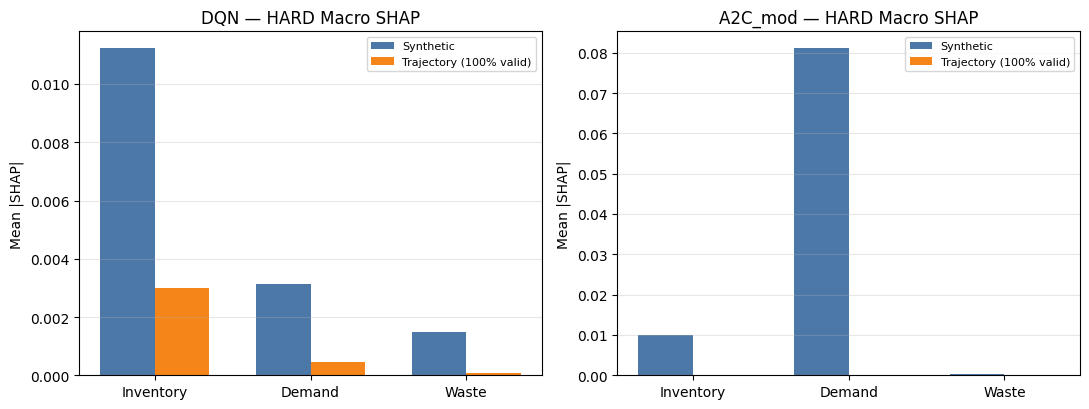

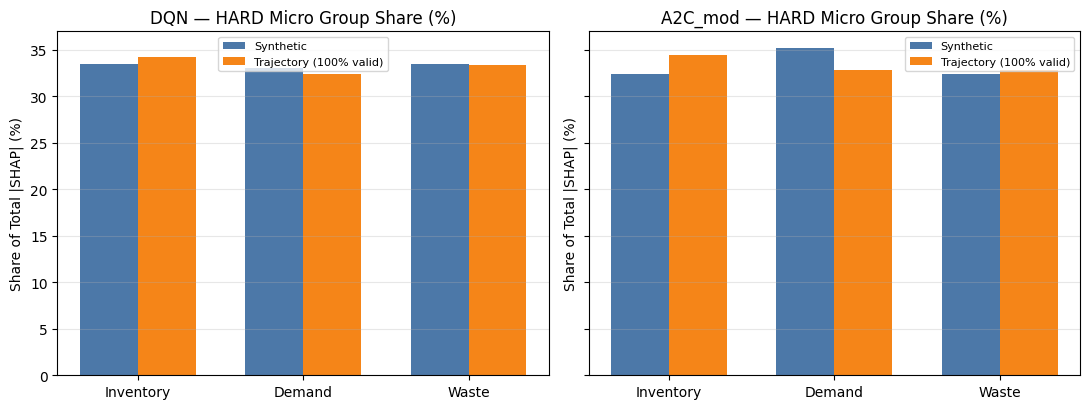

OK: Saved all outputs to c:\GitHub\Q-learning-for-Inventory-Management\Feedback 23-11\task3\output
Files ready for outputTask3.md analysis:
 - hard_macro_shap_comparison.csv
 - hard_macro_shap_details.csv
 - hard_micro_shap_comparison.csv
 - hard_r3_02_combined_table.csv
 - hard_top_skus.csv
 - hard_validity_check.csv
 - task3_summary.json


In [9]:
# Plot 1: Macro SHAP comparison (HARD: Synthetic vs Trajectory)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
x_pos = np.arange(3)
width = 0.35

for ax, ag in zip(axes, ["DQN", "A2C_mod"]):
    imp_syn = macro_imps[(ag, "syn_random_100")]
    imp_traj = macro_imps[(ag, "traj_rollout_100")]
    ax.bar(x_pos - width / 2, imp_syn, width, label="Synthetic", color="#4C78A8")
    ax.bar(x_pos + width / 2, imp_traj, width, label="Trajectory (100% valid)", color="#F58518")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(FEATURE_NAMES_3)
    ax.set_title(f"{ag} — HARD Macro SHAP")
    ax.set_ylabel("Mean |SHAP|")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGS_DIR / "hard_shap_macro_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: Micro SHAP group shares (HARD: Synthetic vs Trajectory)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, ag in zip(axes, ["DQN", "A2C_mod"]):
    row = df_micro_comp[df_micro_comp["agent"] == ag].iloc[0]
    syn_g = [row["syn_inv_pct"], row["syn_dem_pct"], row["syn_wst_pct"]]
    traj_g = [row["traj_inv_pct"], row["traj_dem_pct"], row["traj_wst_pct"]]
    ax.bar(x_pos - width / 2, syn_g, width, label="Synthetic", color="#4C78A8")
    ax.bar(x_pos + width / 2, traj_g, width, label="Trajectory (100% valid)", color="#F58518")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(FEATURE_NAMES_3)
    ax.set_title(f"{ag} — HARD Micro Group Share (%)")
    ax.set_ylabel("Share of Total |SHAP| (%)")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGS_DIR / "hard_shap_micro_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# Save unified JSON summary for fast downstream report generation
summary = {
    "config": {
        "scenario": "HARD",
        "sales_scale": HARD_SALES_SCALE,
        "waste_rate": HARD_WASTE_RATE,
        "n_test": N_TEST,
        "bg_size": BG_SIZE,
        "seed": SEED,
        "a2c_ckpt": str(a2c_latest),
        "dqn_ckpt": str(dqn_latest),
    },
    "validity": df_val.to_dict(orient="records"),
    "macro_details": df_macro.to_dict(orient="records"),
    "macro_comparison": df_macro_comp.to_dict(orient="records"),
    "micro_comparison": df_micro_comp.to_dict(orient="records"),
    "r3_02_table": df_r3_02.to_dict(orient="records"),
}
with open(OUTPUT_DIR / "task3_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"OK: Saved all outputs to {OUTPUT_DIR}")
print("Files ready for outputTask3.md analysis:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(" -", p.name)
